# Niskala – Exploratory Data Analysis

This notebook looks at the harmonized monthly hotspot data for West Kalimantan before we build a forecast model.
The goal is simple: understand the shape of the data so that preprocessing and model choices are based on evidence.

**Data:** harmonized hotspots per month (NOAA-20 equivalent), 14 districts and the province total, July 2002 – October 2026, plus the Niño 3.4 index.
Run steps 1–3 of the pipeline first (`python run_pipeline.py 1 2 3`).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "pipeline"))
from config import INTERIM, ENSO, ENSO_MISSING, HARMONIZED_START_YM, FORECAST_LAST_COMPLETE_YM, PROVINCE

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#898781"
MON = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
pd.set_option("display.width", 140)

## 1. Load the data

In [2]:
h = pd.read_csv(INTERIM / "harmonized_monthly.csv")
h = h[(h.ym >= HARMONIZED_START_YM) & (h.ym <= FORECAST_LAST_COMPLETE_YM)]
P = h.pivot(index="ym", columns="district", values="harmonized")
P[PROVINCE] = P.sum(axis=1)
districts = [d for d in P.columns if d != PROVINCE]
yy, mm = P.index // 100, P.index % 100

rows = []
for line in open(ENSO):
    p = line.split()
    if len(p) == 13 and p[0].isdigit():
        rows += [(int(p[0]) * 100 + k, float(v)) for k, v in enumerate(p[1:], 1)]
enso = pd.Series(dict(rows)).replace(ENSO_MISSING, np.nan)

print(f"{len(P)} months ({P.index.min()} to {P.index.max()}), {len(districts)} districts")
P[[PROVINCE, "Ketapang", "Kubu Raya"]].tail(6).round(0)

292 months (200207 to 202610), 14 districts


district,Kalimantan Barat,Ketapang,Kubu Raya
ym,,,
202605,137.0,24.0,4.0
202606,379.0,109.0,22.0
202607,4257.0,968.0,510.0
202608,37034.0,15880.0,3687.0
202609,24412.0,16675.0,1924.0
202610,9767.0,9289.0,7.0


## 2. Distribution

Fire counts are usually very uneven: most months are quiet, and a few months are huge. We check how many months are zero, how skewed the data is, and whether the variance is much larger than the mean.

In [3]:
stats = pd.DataFrame({
    "zero_%": (P == 0).mean() * 100,
    "mean": P.mean(),
    "median": P.median(),
    "p95": P.quantile(0.95),
    "max": P.max(),
    "var/mean": P.var() / P.mean(),
    "skew": P.skew(),
    "skew_log1p": np.log1p(P).skew(),
}).round(1).sort_values("zero_%")
stats

,zero_%,mean,median,p95,max,var/mean,skew,skew_log1p
district,,,,,,,,
Kalimantan Barat,0.7,3052.0,342.9,16013.9,57588.8,16970.6,4.3,0.2
Ketapang,5.5,983.2,51.8,5870.4,16675.0,6926.7,3.8,0.3
Kubu Raya,12.0,243.9,41.2,1192.1,3769.1,1381.4,4.2,-0.0
Sanggau,16.1,350.2,14.5,2063.8,8538.2,2743.2,4.6,0.6
Bengkayang,18.2,165.1,23.1,790.1,3320.6,1190.1,5.1,0.1
Sambas,18.5,170.6,27.0,820.1,4336.6,1157.3,5.6,0.0
Sintang,20.2,288.6,11.3,1662.4,7073.3,2220.9,5.1,0.6
Mempawah,20.9,95.3,14.1,505.1,1699.8,459.7,4.0,0.1
Landak,21.9,179.6,13.0,985.3,5488.9,1636.9,5.5,0.4


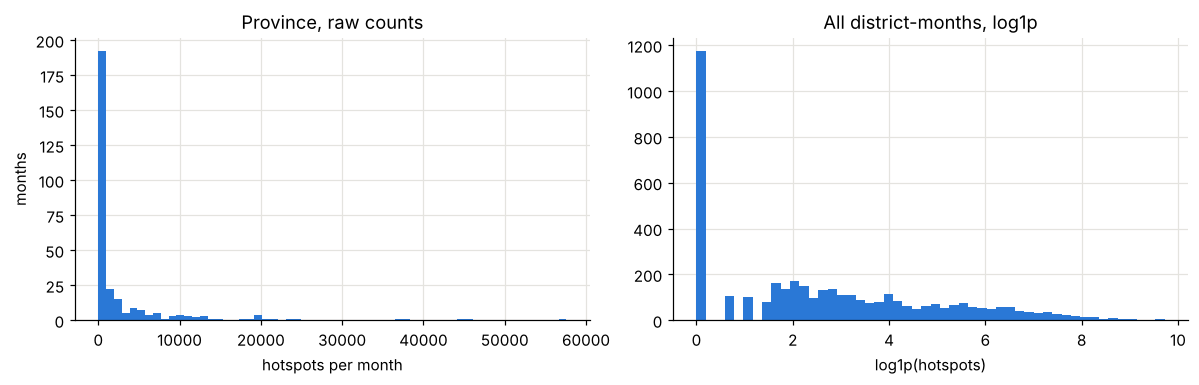

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(P[PROVINCE], bins=60, color=BLUE)
ax[0].set(title="Province, raw counts", xlabel="hotspots per month", ylabel="months")
ax[1].hist(np.log1p(P[districts].to_numpy().ravel()), bins=50, color=BLUE)
ax[1].set(title="All district-months, log1p", xlabel="log1p(hotspots)")
plt.tight_layout()

**Takeaways**
- The variance is hundreds to thousands of times the mean, so the counts are strongly overdispersed.
- Raw counts are very skewed; `log1p` makes them close to symmetric.
- Kota Pontianak and Kota Singkawang are mostly zeros and very small. They are too sparse to model on their own.

## 3. Seasonality

We look at the typical value for each calendar month (median) and the usual spread (25th–75th percentile).

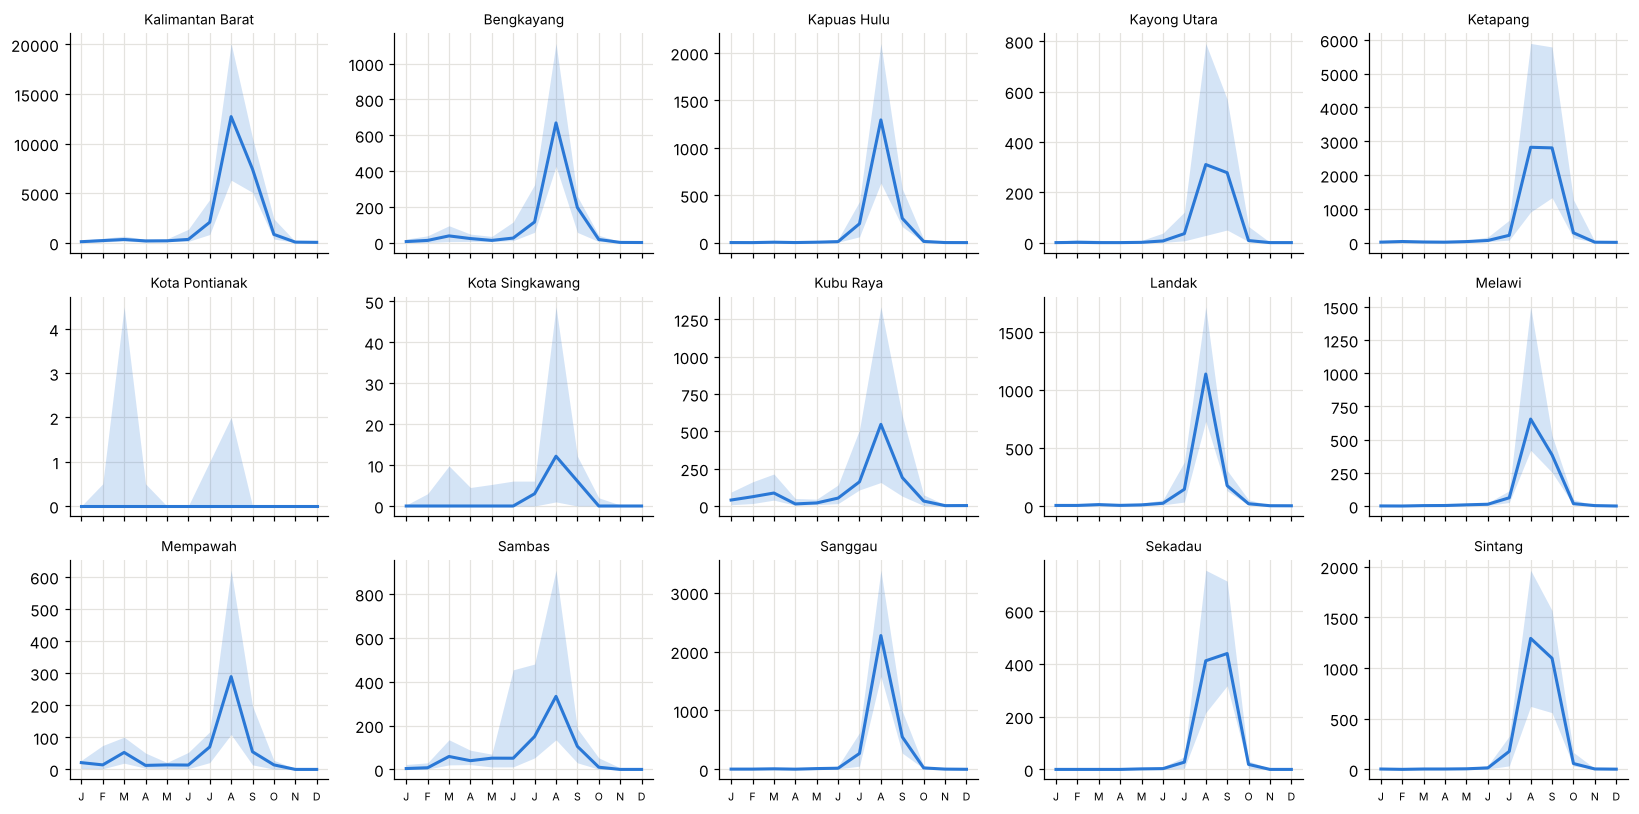

In [5]:
fig, axs = plt.subplots(3, 5, figsize=(15, 7.5), sharex=True)
for a, d in zip(axs.ravel(), [PROVINCE] + districts):
    g = P[d].groupby(mm)
    a.fill_between(range(1, 13), g.quantile(0.25), g.quantile(0.75), color=BLUE, alpha=0.2, lw=0)
    a.plot(range(1, 13), g.median(), color=BLUE, lw=2)
    a.set_title(d, fontsize=9)
    a.set_xticks(range(1, 13))
    a.set_xticklabels(MON, fontsize=7)
plt.tight_layout()

In [6]:
peak_month = P.groupby(yy).idxmax() % 100
season = pd.DataFrame({
    "most_common_peak": peak_month.mode().iloc[0],
    "peak_in_aug_sep_%": peak_month.isin([8, 9]).mean() * 100,
}).round(0)
share_jul_oct = P[PROVINCE][mm.isin([7, 8, 9, 10])].sum() / P[PROVINCE].sum() * 100
print(f"Share of all hotspots in Jul-Oct: {share_jul_oct:.1f}%")
season.sort_values("peak_in_aug_sep_%")

Share of all hotspots in Jul-Oct: 91.3%


,most_common_peak,peak_in_aug_sep_%
district,,
Kota Pontianak,2.0,32.0
Kota Singkawang,8.0,52.0
Sambas,8.0,52.0
Kubu Raya,8.0,64.0
Mempawah,8.0,68.0
Bengkayang,8.0,84.0
Kayong Utara,9.0,88.0
Kapuas Hulu,8.0,92.0
Sintang,8.0,96.0


**Takeaways**
- About 91% of hotspots happen in July–October.
- For most districts the peak is in August or September almost every year.
- Coastal peat districts (Kubu Raya, Sambas, Mempawah) have a less regular peak and a small extra bump in February–March.
- A model needs a month-of-year effect for each district.

## 4. Year-to-year variability

Seasonality tells us *when* fires happen. The harder question is *how much* each year.

Lowest: 8,434  Highest: 76,681  Ratio: 9.1x


ym
2006    76681.0
2026    75470.0
2002    75439.0
2009    67868.0
2004    55604.0
Name: Kalimantan Barat, dtype: float64

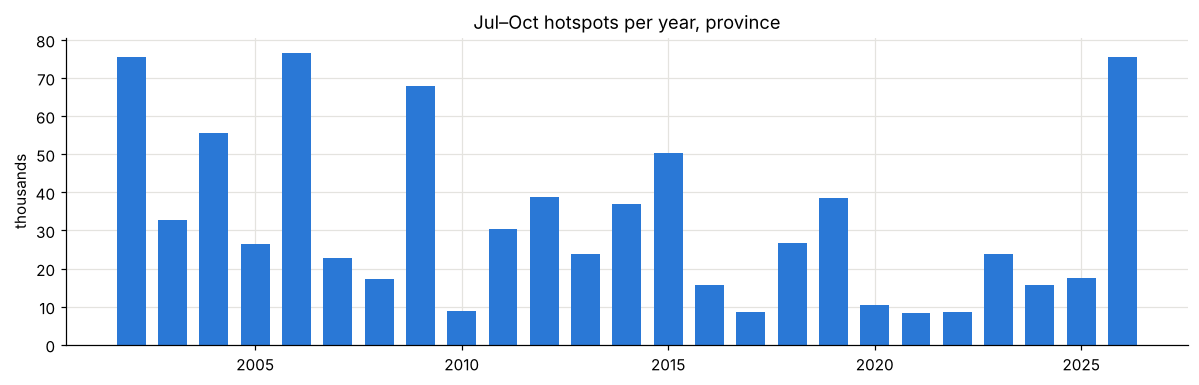

In [7]:
fire_season = P[PROVINCE][mm.isin([7, 8, 9, 10])].groupby(yy[mm.isin([7, 8, 9, 10])]).sum()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(fire_season.index, fire_season / 1000, color=BLUE, width=0.7)
ax.set(title="Jul–Oct hotspots per year, province", ylabel="thousands")
plt.tight_layout()
print(f"Lowest: {fire_season.min():,.0f}  Highest: {fire_season.max():,.0f}  Ratio: {fire_season.max() / fire_season.min():.1f}x")
fire_season.sort_values(ascending=False).head(5).round(0)

**Takeaways**
- The worst fire season is about 9 times the quietest one.
- This year-to-year swing is the main thing a forecast must capture. The seasonal average alone cannot do it.

## 5. ENSO (Niño 3.4)

El Niño brings drought to Indonesia. We check two things: how well ENSO in the months before the season matches the season total, and how many months of lead time still carry a signal.

In [8]:
def shift_ym(ym, k):
    t = (ym // 100) * 12 + (ym % 100 - 1) - k
    return (t // 12) * 100 + t % 12 + 1

windows = {"Jan-Mar": [1, 2, 3], "Mar-May": [3, 4, 5], "Apr-Jun": [4, 5, 6],
           "May-Jul": [5, 6, 7], "Jun-Aug": [6, 7, 8], "Jul-Sep": [7, 8, 9]}
log_season = np.log1p(fire_season)
season_corr = pd.Series({
    name: np.corrcoef([enso[[y * 100 + m for m in ms]].mean() for y in log_season.index], log_season)[0, 1]
    for name, ms in windows.items()
}).round(2)

L = np.log1p(P)
anom = (L - L.groupby(mm).transform("mean"))[PROVINCE]
fs_anom = anom[mm.isin([7, 8, 9, 10])]
lag_corr = pd.Series({
    k: np.corrcoef(enso.reindex([shift_ym(ym, k) for ym in fs_anom.index]), fs_anom)[0, 1]
    for k in range(7)
}).round(2)

pd.DataFrame({"ENSO window vs season total (log)": season_corr}), pd.DataFrame({"ENSO lead (months) vs Jul-Oct monthly anomaly": lag_corr})

(         ENSO window vs season total (log)
 Jan-Mar                              -0.13
 Mar-May                               0.12
 Apr-Jun                               0.38
 May-Jul                               0.56
 Jun-Aug                               0.66
 Jul-Sep                               0.71,
    ENSO lead (months) vs Jul-Oct monthly anomaly
 0                                           0.48
 1                                           0.49
 2                                           0.42
 3                                           0.23
 4                                           0.07
 5                                          -0.05
 6                                          -0.12)

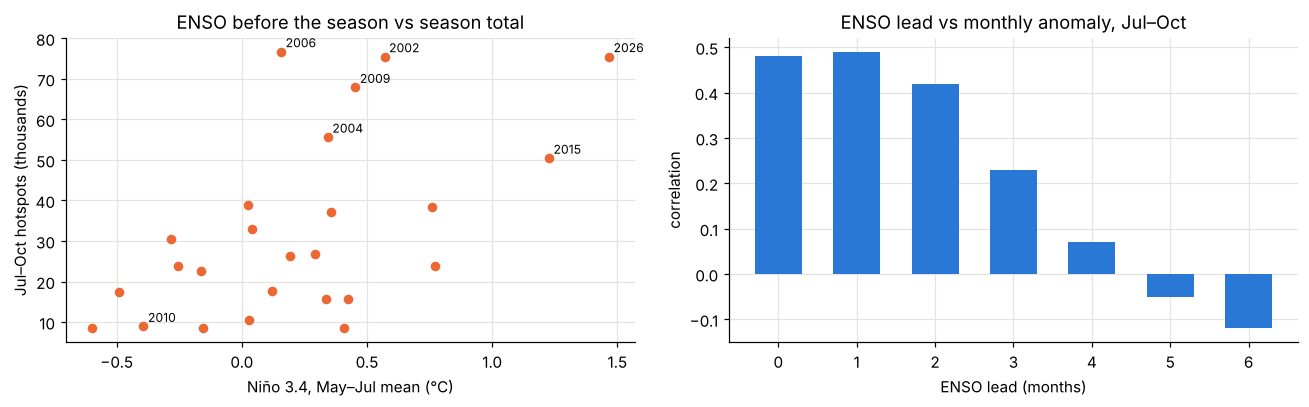

In [9]:
enso_mjj = pd.Series({y: enso[[y * 100 + m for m in [5, 6, 7]]].mean() for y in fire_season.index})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(enso_mjj, fire_season / 1000, color=ORANGE, s=28, zorder=3)
for y in fire_season.nlargest(6).index.tolist() + [2010]:
    ax[0].annotate(str(y), (enso_mjj[y], fire_season[y] / 1000), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[0].set(xlabel="Niño 3.4, May–Jul mean (°C)", ylabel="Jul–Oct hotspots (thousands)", title="ENSO before the season vs season total")
ax[1].bar(lag_corr.index, lag_corr.values, color=BLUE, width=0.6)
ax[1].set(xlabel="ENSO lead (months)", ylabel="correlation", title="ENSO lead vs monthly anomaly, Jul–Oct")
plt.tight_layout()

**Takeaways**
- The closer ENSO is measured to the season, the stronger the link (0.56 for May–Jul, 0.66 for Jun–Aug). Before April there is almost no signal.
- Inside the fire season, ENSO from 0–2 months earlier is useful (about 0.4–0.5). After 3 months it fades.
- Some bad years (2002, 2006, 2009) had only moderate ENSO, so other drivers also matter.
- Use observed ENSO with a 1–2 month lag. Longer lead times would need ENSO forecasts.

## 6. Memory (autocorrelation)

After removing the normal seasonal pattern, how much does one month tell us about the next?

In [10]:
def acf(s, k):
    s = s - s.mean()
    return (s[k:] * s[:-k]).sum() / (s * s).sum()

anom_d = (L - L.groupby(mm).transform("mean"))[districts]
memory = pd.DataFrame({
    "province": {k: acf(anom.to_numpy(), k) for k in (1, 2, 3, 6, 12)},
    "district average": {k: np.mean([acf(anom_d[d].to_numpy(), k) for d in districts]) for k in (1, 2, 3, 6, 12)},
}).round(2)
memory.index.name = "lag (months)"
memory

,province,district average
lag (months),,
1,0.31,0.23
2,0.19,0.15
3,0.06,0.07
6,-0.03,0.02
12,0.04,0.06


**Takeaways**
- Last month matters a little (about 0.2–0.3). By three months the link is gone.
- One or two past months are enough as inputs. A long 12-month window mostly adds noise, which helps explain why the first LSTM overfit.

## 7. Do districts move together?

If districts rise and fall in the same years, one shared model can learn from all of them.

Average correlation between districts: 0.66


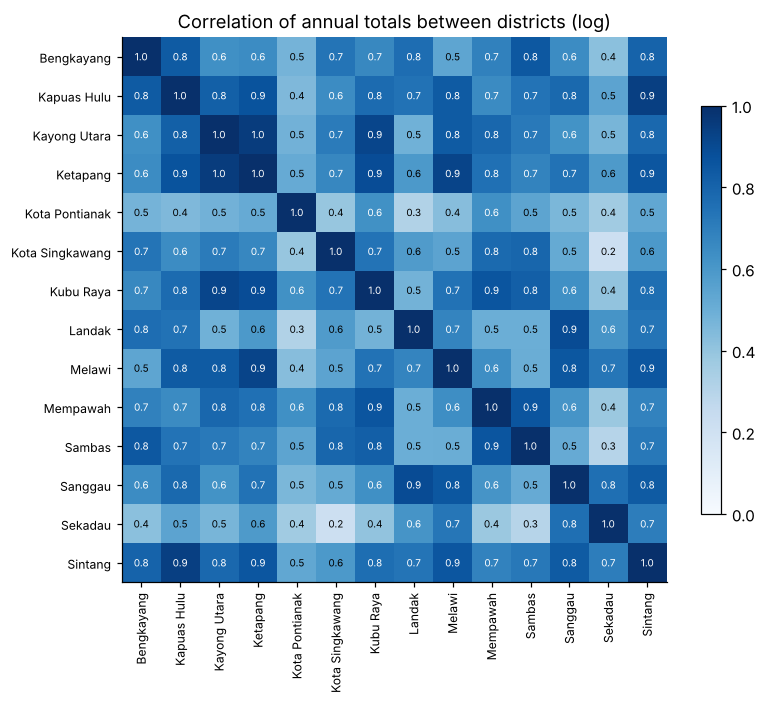

In [11]:
annual = np.log1p(P[districts].groupby(yy).sum())
corr = annual.corr()
mean_offdiag = (corr.to_numpy().sum() - len(corr)) / (len(corr) ** 2 - len(corr))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                color="white" if corr.iloc[i, j] > 0.6 else "black")
fig.colorbar(im, shrink=0.7)
ax.set_title("Correlation of annual totals between districts (log)")
plt.tight_layout()
print(f"Average correlation between districts: {mean_offdiag:.2f}")

**Takeaways**
- Districts are fairly well aligned (average correlation about 0.66): bad years are bad almost everywhere.
- A single pooled model with shared effects and district-specific seasonality makes sense.

## 8. What this means for preprocessing and modeling

| Finding | Decision |
|:---|:---|
| Overdispersed counts with many zeros | Negative Binomial model on counts, or work on `log1p` |
| Pontianak and Singkawang are very sparse | Keep them only in the province total |
| Strong, stable seasonality | Month-of-year effect per district; report Jul–Oct skill separately |
| 9× swing between years | The model needs year-to-year drivers, not only the seasonal average |
| ENSO useful at 1–2 month lead | Use Niño 3.4 lagged 1–2 months; forecast 1 month ahead |
| Short memory | Use only 1–2 lagged anomalies |
| Districts move together | One pooled model with shared ENSO and lag effects |

Main model: **Negative Binomial regression**. Baselines: **climatology** and **persistence**. The **LSTM** stays as an experiment with a short input window.